<a href="https://colab.research.google.com/github/SalehinShan/smart-service-complaint-understanding/blob/main/slscData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!pip install pandas openpyxl scikit-learn


In [2]:

import os

print(os.listdir("/content"))


['.config', 'BanglaPSG_1000_Complaints_Translated.xlsx', 'sample_data']


In [3]:
import pandas as pd

file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'

# Load and inspect sheets/data
xl = pd.ExcelFile(file_path)
print("Sheet names:", xl.sheet_names)

df_variants = pd.read_excel(file_path)
print("Dataset Shape:", df_variants.shape)
print("\nColumns:")
print(df_variants.columns.tolist())

print("\nFirst 3 rows:")
display(df_variants.head(3))

print("\nMissing values per column:")
print(df_variants.isnull().sum())

Sheet names: ['Complaints_Translated', 'Summary']
Dataset Shape: (1000, 9)

Columns:
['Sample ID', 'Original No.', 'Category', 'Severity', 'Original Complaint (Bangla)', 'Banglish', 'English', 'Code-Mixed', 'Slang']

First 3 rows:


,Sample ID,Original No.,Category,Severity,Original Complaint (Bangla),Banglish,English,Code-Mixed,Slang
0,1,1642,Waste,Low,সানকীপাড়া নতুন পল্লী এলাকায় ময়লাবাহী গাড়ী সপ্ত...,Sankipara Notun Polli elakay moylabahi gari so...,The garbage truck doesn't come more than twice...,Sankipara Notun Polli area তে garbage truck we...,সানকীপাড়া নতুন পল্লীতে ময়লার গাড়ি হপ্তায় দ...
1,2,1055,Healthcare,High,ইবনে সিনা হাসপাতালের ভুল আলটার কারনে আমার বাচ্...,Ibne Sina hospital er bhul ultra-r karone amar...,My baby died because of a wrong ultrasound at ...,Ibne Sina Hospital এর wrong ultrasound report ...,ইবনে সিনার ভুয়া আলট্রার জন্য আমার বাচ্চাটা মই...
2,3,1485,Food,Medium,"ঢাকার, ডেমরা এলাকার স্টাফকোয়াটার এরিয়াতে অনে...",Dhakar Demra elakar Staff Quarter area-te onek...,There are many restaurants and food courts in ...,Dhaka-র Demra-র Staff Quarter area তে অনেক res...,ডেমরার স্টাফ কোয়াটারে হুদাই রেস্টুরেন্ট আর ফু...



Missing values per column:
Sample ID                      0
Original No.                   0
Category                       0
Severity                       0
Original Complaint (Bangla)    0
Banglish                       0
English                        0
Code-Mixed                     0
Slang                          0
dtype: int64


### Training and Evaluation strictly on the 1,000 Translated Complaints
We will partition the 1,000 complaints into 80% train and 20% test splits. The training set will be augmented by flattening all five columns (`Original Complaint (Bangla)`, `Banglish`, `English`, `Code-Mixed`, and `Slang`) so that the TF-IDF Vectorizer learns a multi-script vocabulary.

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the 1,000 Translated Complaints
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)

# Normalize categories
df_new['Category'] = df_new['Category'].astype(str).str.strip()

# 2. Stratified train/test split (80/20) at the row level
train_idx, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)

train_df = df_new.loc[train_idx].copy()
test_df = df_new.loc[test_idx].copy()

# 3. Augment Training Set by flattening the 5 text columns
augmented_train_records = []
eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

for idx, row in train_df.iterrows():
    category = row['Category']
    for lang_label, col_name in eval_cols.items():
        text_val = str(row[col_name]).strip()
        if text_val:
            augmented_train_records.append({
                'Text': text_val,
                'Category': category
            })

df_train_augmented = pd.DataFrame(augmented_train_records)
print(f"Original Train Rows: {len(train_df)}")
print(f"Augmented Train Samples (5 variants flattened): {len(df_train_augmented)}")
print(f"Test Rows: {len(test_df)}")

# 4. Define and Train the new Multilingual SVM Pipeline
multilingual_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=30000)),
    ('clf', LinearSVC(C=1.0, random_state=42, class_weight='balanced'))
])

multilingual_pipeline.fit(df_train_augmented['Text'], df_train_augmented['Category'])
print("\nMultilingual Pipeline Successfully Trained!")

# Save this new model
joblib.dump(multilingual_pipeline, '/content/multilingual_grievance_svm_pipeline.pkl')
print("Saved new model to /content/multilingual_grievance_svm_pipeline.pkl")

Original Train Rows: 800
Augmented Train Samples (5 variants flattened): 4000
Test Rows: 200

Multilingual Pipeline Successfully Trained!
Saved new model to /content/multilingual_grievance_svm_pipeline.pkl


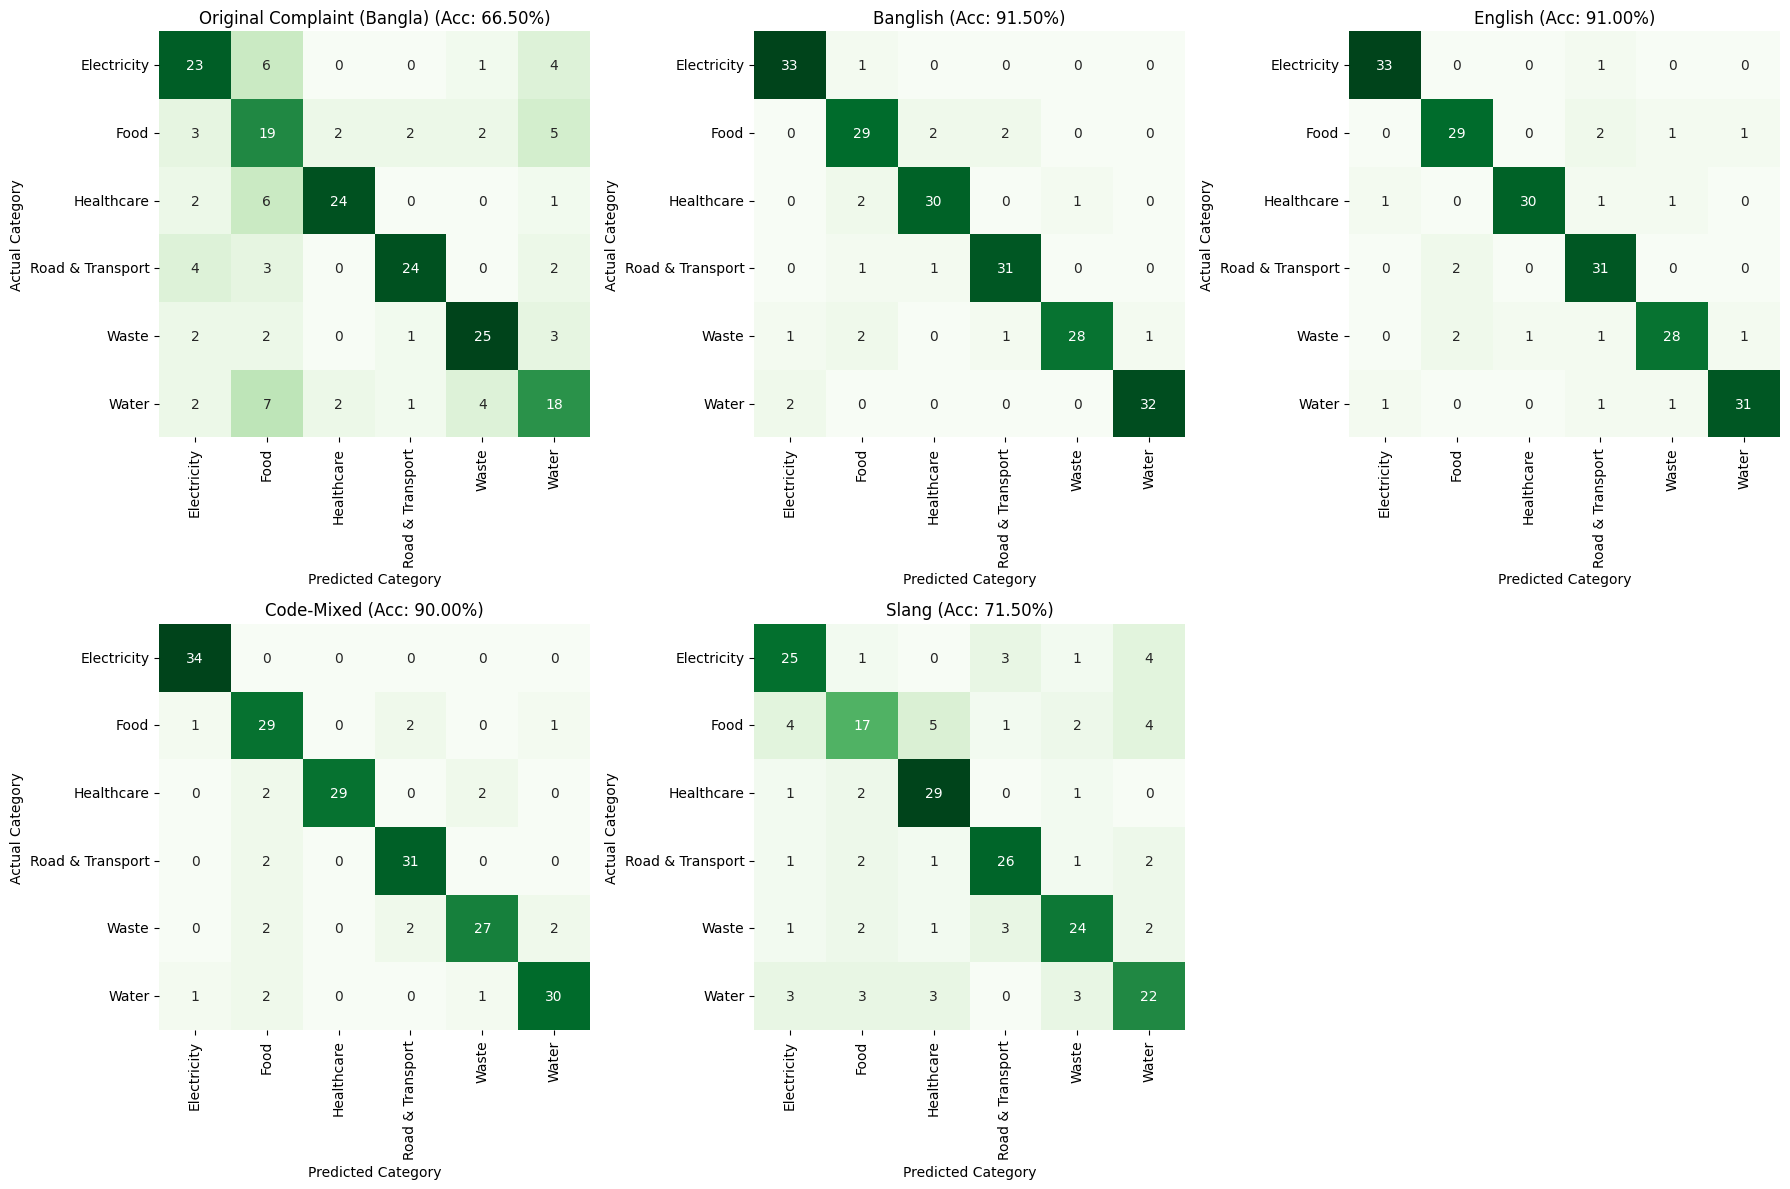

=== NEW ROBUSTNESS SUMMARY ON TEST SPLIT (200 RECS) ===
Original Complaint (Bangla)    | Accuracy: 0.6650
Banglish                       | Accuracy: 0.9150
English                        | Accuracy: 0.9100
Code-Mixed                     | Accuracy: 0.9000
Slang                          | Accuracy: 0.7150


In [5]:
# 5. Evaluate the Multilingual model on the Test Set (200 records) across all 5 variants
y_true_test = test_df['Category'].astype(str).str.strip()
classes = multilingual_pipeline.classes_

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

new_results = {}

for idx, (label, col_name) in enumerate(eval_cols.items()):
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_variant = multilingual_pipeline.predict(X_test_variant)

    acc = accuracy_score(y_true_test, y_pred_variant)
    new_results[label] = acc

    cm = confusion_matrix(y_true_test, y_pred_variant, labels=classes)

    sns.heatmap(cm, annot=True, fmt='d', xticklabels=classes, yticklabels=classes,
                cmap='Greens', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{label} (Acc: {acc:.2%})")
    axes[idx].set_ylabel('Actual Category')
    axes[idx].set_xlabel('Predicted Category')

axes[5].axis('off')
plt.tight_layout()
plt.show()

print("=== NEW ROBUSTNESS SUMMARY ON TEST SPLIT (200 RECS) ===")
for label, acc in new_results.items():
    print(f"{label:<30} | Accuracy: {acc:.4f}")

In [6]:
import joblib
import pandas as pd
from sklearn.metrics import classification_report

# Load dataset and pipeline
file_path = '/content/BanglaPSG_1000_Complaints_Translated.xlsx'
df_new = pd.read_excel(file_path)
multilingual_pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')

# Isolate the identical 20% test split index used for validation
from sklearn.model_selection import train_test_split
df_new['Category'] = df_new['Category'].astype(str).str.strip()
_, test_idx = train_test_split(
    df_new.index,
    test_size=0.20,
    random_state=42,
    stratify=df_new['Category']
)
test_df = df_new.loc[test_idx]
y_true_test = test_df['Category']

eval_cols = {
    'Original Complaint (Bangla)': 'Original Complaint (Bangla)',
    'Banglish': 'Banglish',
    'English': 'English',
    'Code-Mixed': 'Code-Mixed',
    'Slang': 'Slang'
}

# Generate and print a comprehensive report for each variant
for label, col_name in eval_cols.items():
    print(f"\n{'='*20} {label.upper()} CLASSIFICATION REPORT {'='*20}")
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_variant = multilingual_pipeline.predict(X_test_variant)
    print(classification_report(y_true_test, y_pred_variant, zero_division=0))


==================== ORIGINAL COMPLAINT (BANGLA) CLASSIFICATION REPORT ====================
                  precision    recall  f1-score   support

     Electricity       0.64      0.68      0.66        34
            Food       0.44      0.58      0.50        33
      Healthcare       0.86      0.73      0.79        33
Road & Transport       0.86      0.73      0.79        33
           Waste       0.78      0.76      0.77        33
           Water       0.55      0.53      0.54        34

        accuracy                           0.67       200
       macro avg       0.69      0.67      0.67       200
    weighted avg       0.69      0.67      0.67       200


==================== BANGLISH CLASSIFICATION REPORT ====================
                  precision    recall  f1-score   support

     Electricity       0.92      0.97      0.94        34
            Food       0.83      0.88      0.85        33
      Healthcare       0.91      0.91      0.91        33
Road & Transport 

In [7]:
import numpy as np
import joblib

# Load the pipeline
pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')
vectorizer = pipeline.named_steps['tfidf']
classifier = pipeline.named_steps['clf']

# Get feature names
feature_names = np.array(vectorizer.get_feature_names_out())
classes = classifier.classes_

print("=== TOP 10 INFLUENTIAL FEATURES PER CATEGORY ===\n")
for i, class_name in enumerate(classes):
    # For LinearSVC, coef_ has shape (n_classes, n_features)
    coefs = classifier.coef_[i]
    top_indices = np.argsort(coefs)[-10:][::-1]
    top_features = feature_names[top_indices]
    top_weights = coefs[top_indices]

    print(f"Category: {class_name.upper()}")
    print(f"{'Feature':<30} | {'Weight':<10}")
    print("-" * 45)
    for feature, weight in zip(top_features, top_weights):
        print(f"{feature:<30} | {weight:.4f}")
    print("\n" + "="*50 + "\n")

=== TOP 10 INFLUENTIAL FEATURES PER CATEGORY ===

Category: ELECTRICITY
Feature                        | Weight    
---------------------------------------------
electricity                    | 4.0508
biddut                         | 4.0348
পল                             | 3.8935
bidyut                         | 3.1268
meter                          | 2.9219
power                          | 2.7498
palli bidyut                   | 1.9676
palli                          | 1.9676
ইড                             | 1.9652
ইউন                            | 1.9313


Category: FOOD
Feature                        | Weight    
---------------------------------------------
food                           | 3.6911
bhejal                         | 2.4483
তরম                            | 1.9979
khabar                         | 1.9172
bsti                           | 1.7912
ওজন                            | 1.7696
লওয                            | 1.6750
অধ                             | 1.6073
adulteratio

In [8]:
import joblib
import ipywidgets as widgets
from IPython.display import display, clear_output

# 1. Load the trained pipeline
try:
    pipeline = joblib.load('/content/multilingual_grievance_svm_pipeline.pkl')
    print("✅ Multilingual SVM model loaded successfully.")
except Exception as e:
    print(f"❌ Error loading model: {e}")

# 2. Setup interactive widgets
text_input = widgets.Textarea(
    value='',
    placeholder='Type your municipal grievance here...',
    description='Grievance:',
    layout=widgets.Layout(width='80%', height='100px')
)

button = widgets.Button(
    description='Classify Grievance',
    button_style='success',
    tooltip='Click to run inference',
    icon='search'
)

output = widgets.Output()

def on_button_click(b):
    with output:
        clear_output()
        query = text_input.value.strip()
        if not query:
            print("Please enter some text to classify.")
            return

        # Run prediction
        prediction = pipeline.predict([query])[0]

        # Calculate confidence estimate using decision function distances
        decision_values = pipeline.decision_function([query])[0]
        # Display results
        print(f"Raw Query: \"{query}\"\n")
        print(f"Predicted Category: {prediction.upper()}")
        print("-" * 50)
        print("Category Match Confidence Strengths (Higher is better):")
        for cls, score in zip(pipeline.classes_, decision_values):
            indicator = "⭐️" if cls == prediction else "  "
            print(f"{indicator} {cls:<20}: {score:.4f}")

button.on_click(on_button_click)

# 3. Display the Interface
display(widgets.VBox([
    widgets.HTML("<h3>Multilingual Complaints Classifier - Live Testing</h3>"),
    text_input,
    button,
    output
]))

✅ Multilingual SVM model loaded successfully.


**Reasoning**:
Install transformers and torch to prepare for loading the Hugging Face zero-shot classification pipeline.



In [9]:
!pip install transformers torch

**Reasoning**:
I will initialize the Hugging Face zero-shot classification pipeline using the 'MoritzLaurer/mDeBERTa-v3-base-mnli-xnli' model, detect if GPU is available, and verify its operation with a simple test query.



In [10]:
import torch
from transformers import pipeline
import warnings
warnings.filterwarnings('ignore')

# 1. Check for GPU availability
device = 0 if torch.cuda.is_available() else -1
print(f"Using device: {'GPU (cuda)' if device == 0 else 'CPU'}")

# 2. Initialize the Zero-Shot Classification Pipeline
model_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
print(f"Loading zero-shot classification model: {model_name}...")
zero_shot_classifier = pipeline(
    "zero-shot-classification",
    model=model_name,
    device=device
)
print("✅ Zero-shot classification pipeline loaded successfully!")

# 3. Quick test inference
test_text = "আমাদের এলাকায় পানির কোনো লাইন নাই, আমরা কি খাবো?"
target_labels = ["Electricity", "Food", "Healthcare", "Road & Transport", "Waste", "Water"]

test_res = zero_shot_classifier(test_text, target_labels, multi_label=False)
print(f"\nTest Text: \"{test_text}\"")
print(f"Predicted: {test_res['labels'][0]} with score {test_res['scores'][0]:.4f}")

Using device: GPU (cuda)
Loading zero-shot classification model: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli...


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

✅ Zero-shot classification pipeline loaded successfully!

Test Text: "আমাদের এলাকায় পানির কোনো লাইন নাই, আমরা কি খাবো?"
Predicted: Road & Transport with score 0.3326


**Reasoning**:
We will run zero-shot inference with mDeBERTa on the 200 test set rows across all 5 language variants and store the predictions in a dictionary.



In [11]:
from tqdm.notebook import tqdm
import numpy as np
import pandas as pd

# Initialize dictionary to store predictions
# Structure: {variant_name: [list of 200 predictions]}
zero_shot_preds = {
    'Original Complaint (Bangla)': [],
    'Banglish': [],
    'English': [],
    'Code-Mixed': [],
    'Slang': []
}

# Target categories
target_labels = ['Electricity', 'Food', 'Healthcare', 'Road & Transport', 'Waste', 'Water']

# Iterate over the 5 variants
for label, col_name in eval_cols.items():
    print(f"Running Zero-Shot Inference for: {label}...")
    texts = test_df[col_name].astype(str).str.strip().tolist()

    # Batch processing or direct loop
    preds = []
    for text in tqdm(texts):
        if not text:
            preds.append('Water') # Fallback default
            continue
        res = zero_shot_classifier(text, target_labels, multi_label=False)
        preds.append(res['labels'][0])

    zero_shot_preds[label] = preds

# Verify predictions shape
for label, preds in zero_shot_preds.items():
    print(f"{label}: {len(preds)} predictions successfully generated.")


Running Zero-Shot Inference for: Original Complaint (Bangla)...


  0%|          | 0/200 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Running Zero-Shot Inference for: Banglish...


  0%|          | 0/200 [00:00<?, ?it/s]

Running Zero-Shot Inference for: English...


... (2 outputs left out)

  0%|          | 0/200 [00:00<?, ?it/s]

Running Zero-Shot Inference for: Slang...


  0%|          | 0/200 [00:00<?, ?it/s]

Original Complaint (Bangla): 200 predictions successfully generated.
Banglish: 200 predictions successfully generated.
English: 200 predictions successfully generated.
Code-Mixed: 200 predictions successfully generated.
Slang: 200 predictions successfully generated.


## Performance Comparison: Zero-Shot vs. Multilingual SVM

### Subtask:
Compute accuracy, F1-scores, and detailed classification reports for both models across all five language variants.

In [12]:
from sklearn.metrics import accuracy_score, f1_score, classification_report
import pandas as pd

# Initialize a list to hold consolidated metrics for easy comparison
comparison_metrics = []

# Ensure we have ground truth aligned
y_true = test_df['Category'].astype(str).str.strip().tolist()

for label, col_name in eval_cols.items():
    # 1. SVM predictions
    X_test_variant = test_df[col_name].astype(str).str.strip()
    y_pred_svm = multilingual_pipeline.predict(X_test_variant)

    # 2. Zero-shot predictions
    y_pred_zs = zero_shot_preds[label]

    # Calculate SVM metrics
    acc_svm = accuracy_score(y_true, y_pred_svm)
    f1_svm = f1_score(y_true, y_pred_svm, average='macro')

    # Calculate Zero-Shot metrics
    acc_zs = accuracy_score(y_true, y_pred_zs)
    f1_zs = f1_score(y_true, y_pred_zs, average='macro')

    comparison_metrics.append({
        'Variant': label,
        'SVM Accuracy': acc_svm,
        'SVM F1-Macro': f1_svm,
        'Zero-Shot Accuracy': acc_zs,
        'Zero-Shot F1-Macro': f1_zs
    })

    # Display detailed classification reports side-by-side/sequentially
    print(f"\n{'='*30} VARIANT: {label.upper()} {'='*30}")
    print("\n--- MULTILINGUAL SVM CLASSIFICATION REPORT ---")
    print(classification_report(y_true, y_pred_svm, zero_division=0))

    print("\n--- ZERO-SHOT MDEBERTA CLASSIFICATION REPORT ---")
    print(classification_report(y_true, y_pred_zs, zero_division=0))

# Convert comparison metrics to DataFrame for rich visualization
df_comparison = pd.DataFrame(comparison_metrics)
display(df_comparison)


============================== VARIANT: ORIGINAL COMPLAINT (BANGLA) ==============================

--- MULTILINGUAL SVM CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

     Electricity       0.64      0.68      0.66        34
            Food       0.44      0.58      0.50        33
      Healthcare       0.86      0.73      0.79        33
Road & Transport       0.86      0.73      0.79        33
           Waste       0.78      0.76      0.77        33
           Water       0.55      0.53      0.54        34

        accuracy                           0.67       200
       macro avg       0.69      0.67      0.67       200
    weighted avg       0.69      0.67      0.67       200


--- ZERO-SHOT MDEBERTA CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

     Electricity       1.00      0.85      0.92        34
            Food       0.83      0.61      0.70        33
      Healthcare       0.93      0.76      0

,Variant,SVM Accuracy,SVM F1-Macro,Zero-Shot Accuracy,Zero-Shot F1-Macro
0,Original Complaint (Bangla),0.665,0.672910,0.745,0.758354
1,Banglish,0.915,0.914785,0.360,0.347236
2,English,0.910,0.909816,0.675,0.695876
3,Code-Mixed,0.900,0.899986,0.705,0.718814
4,Slang,0.715,0.711710,0.680,0.700035


## Visualize Comparative Analysis

### Subtask:
Generate comparative bar charts showing Accuracy and F1-Macro scores side-by-side for the Supervised Multilingual SVM and the Zero-Shot mDeBERTa model across all 5 language variants.

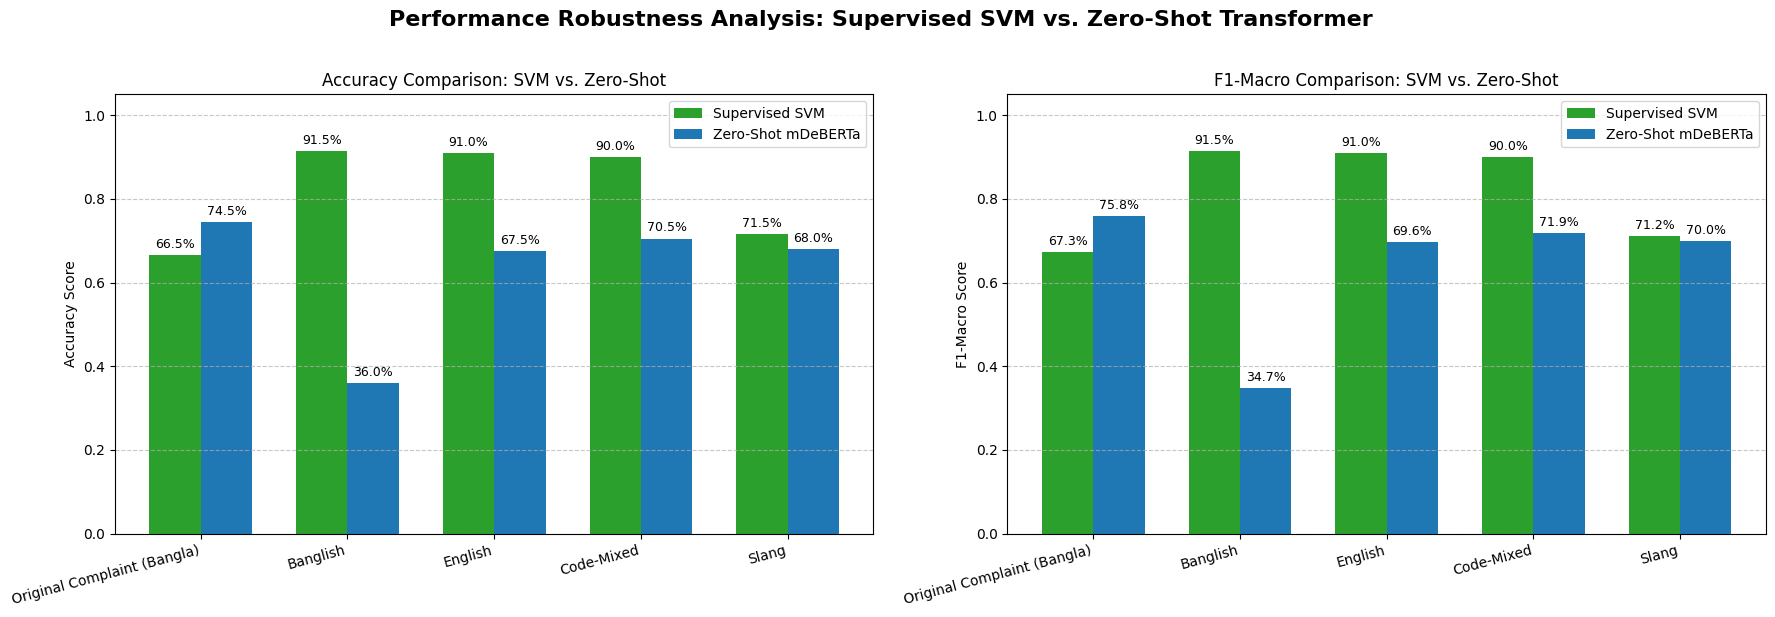

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data from our comparison dataframe
variants = df_comparison['Variant'].tolist()
x = np.arange(len(variants))  # label locations
width = 0.35  # width of the bars

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# 1. Plot Accuracy comparison
rects1_acc = ax1.bar(x - width/2, df_comparison['SVM Accuracy'], width, label='Supervised SVM', color='#2ca02c')
rects2_acc = ax1.bar(x + width/2, df_comparison['Zero-Shot Accuracy'], width, label='Zero-Shot mDeBERTa', color='#1f77b4')

ax1.set_ylabel('Accuracy Score')
ax1.set_title('Accuracy Comparison: SVM vs. Zero-Shot')
ax1.set_xticks(x)
ax1.set_xticklabels(variants, rotation=15, ha='right')
ax1.set_ylim(0, 1.05)
ax1.legend()
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# Add values on top of bars for Accuracy
def autolabel(rects, ax):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1%}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1_acc, ax1)
autolabel(rects2_acc, ax1)

# 2. Plot F1-Macro comparison
rects1_f1 = ax2.bar(x - width/2, df_comparison['SVM F1-Macro'], width, label='Supervised SVM', color='#2ca02c')
rects2_f1 = ax2.bar(x + width/2, df_comparison['Zero-Shot F1-Macro'], width, label='Zero-Shot mDeBERTa', color='#1f77b4')

ax2.set_ylabel('F1-Macro Score')
ax2.set_title('F1-Macro Comparison: SVM vs. Zero-Shot')
ax2.set_xticks(x)
ax2.set_xticklabels(variants, rotation=15, ha='right')
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(axis='y', linestyle='--', alpha=0.7)

autolabel(rects1_f1, ax2)
autolabel(rects2_f1, ax2)

plt.suptitle('Performance Robustness Analysis: Supervised SVM vs. Zero-Shot Transformer', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Task
Evaluate zero-shot text classification performance using a robust multilingual model (such as `"MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"`) on the 200 test set rows from the dataset `"/content/BanglaPSG_1000_Complaints_Translated.xlsx"` across its 5 language variants (Original Bangla, Banglish, English, Code-Mixed, and Slang). You must run the zero-shot inference, map predictions to the target municipal categories (`"Electricity"`, `"Food"`, `"Healthcare"`, `"Road & Transport"`, `"Waste"`, `"Water"`), compute comparative performance metrics (accuracy, F1-scores, classification reports) with the previously trained Multilingual SVM model `"/content/multilingual_grievance_svm_pipeline.pkl"`, generate comparative visualizations, and discuss the strengths and weaknesses of zero-shot classification versus the supervised SVM pipeline.

## Load Zero-Shot Pipeline

### Subtask:
Initialize a Hugging Face zero-shot classification pipeline using a robust multilingual NLI model.


## Run Zero-Shot Inference

### Subtask:
Evaluate the zero-shot classifier model on the 200 test set rows across all 5 language variants.
